# 지능형 CCTV 관제 판단 실험 — 전체 분석 노트북

데이터사이언스개론 팀 프로젝트 · 자동화 편향(automation bias) 실험

**이 노트북 하나로** 원자료 읽기 → 전처리 → EDA → KPI 계산 → 통계 검정(p값) → 민감도 분석 → 발표용 차트까지 모두 재현한다.

| 순서 | 내용 |
|---|---|
| 0 | 환경 설정 (경로, 한글 폰트) |
| 1 | 원자료 읽기 |
| 2 | 전처리 (분석 대상 선정·제외 기준) |
| 3 | EDA (참가자 구성, 분포, 기본 기술통계) |
| 4 | 참가자별 KPI 계산 (오탐 수용률, 정탐 신고율, 판별력 d′, 기준 c, 균형 정답률) |
| 5 | 가설 검정 (그룹 비교, AI 없이 기준선 비교) |
| 6 | G3 내부 분석 (AI 보기 전 → 후, 판단 전환) |
| 7 | 장면·유형 단위 분석 |
| 8 | 판단 시간·확신도·학습 효과 |
| 9 | 설문 vs 행동 (상관 분석) |
| 10 | 민감도 분석·검정력 |
| 11 | 발표용 차트 9장 |
| 12 | 결과 요약 |

**폴더 구조** — 이 노트북을 실험 폴더(`07.지능형_관제_서비스_CCTV_영상_데이터`)에 두고 실행한다.
```
data_1123/data.csv              ← PsyToolkit 설문 데이터
data_1123/experiment_data/*.txt ← PsyToolkit 실험 데이터 (참가자별)
scenes.csv                      ← 장면 정보 (정답, 라벨, 주야, 줌)
```

## 0. 환경 설정

In [1]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
from scipy import stats
from scipy.stats import norm
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

SRC = "data_1123"          # PsyToolkit 데이터 폴더
SCENES = "scenes.csv"      # 장면 정보
OUT = "results/charts"     # 차트 저장 폴더
os.makedirs(OUT, exist_ok=True)

# 한글 폰트: Windows(맑은 고딕) → Mac(AppleGothic) → 리눅스(Noto) 순서로 찾기
for f in fm.findSystemFonts():
    if "NotoSansCJK" in f: fm.fontManager.addfont(f)
names = {f.name for f in fm.fontManager.ttflist}
FONT = next((n for n in ["Malgun Gothic", "AppleGothic", "Noto Sans CJK KR", "NanumGothic"] if n in names), None)
if FONT: mpl.rcParams["font.family"] = FONT
else: print("⚠ 한글 폰트를 찾지 못했습니다. 차트의 한글이 깨질 수 있습니다 (Windows는 맑은 고딕이 기본 설치되어 있음).")
mpl.rcParams.update({"axes.unicode_minus": False, "font.size": 12,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": "#bbbbbb", "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e6e6",
    "axes.axisbelow": True, "xtick.color": "#444", "ytick.color": "#666", "figure.dpi": 110})
print("한글 폰트:", FONT)

GNAME = {1: "G1 라벨", 2: "G2 보고서", 3: "G3 선판단"}
COL = {"G1": "#257de0", "G2": "#f47230", "G3": "#00b894", "noAI": "#9a9a9a"}   # 색약 검증 통과 팔레트

한글 폰트: Noto Sans CJK KR


## 1. 원자료 읽기

PsyToolkit은 두 종류의 파일을 준다.
- `data.csv`: 설문 응답. 한 줄 = 참가자 한 명. 그룹(`psy_group`), 사후 설문, 인구통계, 실험 파일 이름(`exp_g1/2/3`)이 들어 있다.
- `experiment_data/*.txt`: 실험 응답. 한 줄 = 판단 한 번. 공백으로 구분된 숫자/글자.

실험 파일 열 구조 (scene 0 = 연습 장면, 분석 제외):
- **G1·G2 (10열)**: block · trial · scene · truth · label · attn · choice · rt · conf · confrt
- **G3 (12열)**: block · trial · scene · truth · label · attn · **firstchoice · firstrt** · choice · rt · conf · confrt

`choice` 1 = 신고, 2 = 무시 · `rt` 밀리초 · `conf` 확신도 1~5 · `truth` 1 = 정탐(AI 맞음), 0 = 오탐(AI 틀림)

In [2]:
survey = pd.read_csv(f"{SRC}/data.csv", encoding="utf-8-sig", dtype=str).fillna("")
scenes = pd.read_csv(SCENES, encoding="utf-8-sig").rename(columns={"scene_id": "scene"})
print("설문 시작:", len(survey), "명")
print("실험 파일:", len(glob.glob(f"{SRC}/experiment_data/*.txt")), "개")
print("열:", survey.columns.tolist())

설문 시작: 145 명
실험 파일: 127 개
열: ['participant', 'psy_group', 'repeat_check', 'exp_notice', 'exp_g1', 'exp_g2', 'exp_g3', 'post_trust_1', 'post_trust_2', 'post_trust_3', 'post_trust_g2_1', 'post_trust_g2_2', 'post_trust_g2_3', 'basis_g1_1', 'basis_g1_2', 'basis_g2_1', 'basis_g2_2', 'basis_g2_3', 'basis_g3_1', 'basis_g3_2', 'ai_use', 'ai_trust_general', 'cctv_exp', 'device', 'age', 'gender', 'debrief', 'already_done', 'CLIENT_start', 'TIME_start', 'TIME_end', 'TIME_total']


In [3]:
# 실험 파일 하나 열어 보기
f = survey.loc[survey.exp_g3 != "", "exp_g3"].iloc[0]
print("".join(open(f"{SRC}/experiment_data/{f}", encoding="utf-8").readlines()[:4]))

3 3 0 -1 0 0 1 4463 1 1318 5 2270
5 5 S15 0 쓰러짐 0 1 2568 1 1803 4 1932
5 6 S04 1 싸움 0 1 1802 1 1487 5 1116
5 7 S11 1 침입 0 1 1802 1 769 5 1317



## 2. 전처리

### 2-1. 판단 단위 데이터(trial-level) 만들기

참가자마다 실험 파일을 열어 판단 한 줄씩 표로 쌓는다. 이때 아래 경우는 건너뛴다.
1. 그룹 배정이 없거나 실험 파일이 없는 경우 (중도 이탈)
2. **배정 그룹과 실제로 실행된 실험이 다른 경우** (파일명 `cctv_gN`의 N ≠ `psy_group`)
3. 본 실험 18장면을 다 하지 않은 경우
4. 사후 설문을 끝내지 않은 경우 (마지막 문항인 성별 미응답)

In [4]:
rows, log = [], {"그룹/파일 없음": 0, "그룹-실험 불일치": 0, "18장면 미완료": 0, "사후설문 미완료": 0}
for _, r in survey.iterrows():
    ef = r.exp_g1 or r.exp_g2 or r.exp_g3
    path = f"{SRC}/experiment_data/{ef}"
    if not r.psy_group or not ef or not os.path.exists(path):
        log["그룹/파일 없음"] += 1; continue
    g = int(r.psy_group)
    if int(ef.split(".")[0][-1]) != g:
        log["그룹-실험 불일치"] += 1; continue
    lines = [l.split() for l in open(path, encoding="utf-8") if l.strip()]
    main = [x for x in lines if x[2] != "0"]              # 연습 장면 제외
    if len(main) < 18:
        log["18장면 미완료"] += 1; continue
    if not r.gender:
        log["사후설문 미완료"] += 1; continue
    for pos, x in enumerate(main, 1):                       # pos = 그 사람이 본 순서 (무작위)
        if g == 3:
            _, _, sc, t, lab, _, c1, rt1, c2, rt2, conf, _ = x[:12]
        else:
            _, _, sc, t, lab, _, c2, rt2, conf, _ = x[:10]; c1 = rt1 = None
        rows.append(dict(pid=r.participant, group=g, pos=pos, scene=sc, truth=int(t), label=lab,
                         first=None if c1 is None else float(int(c1) == 1),
                         first_rt=None if rt1 is None else int(rt1),
                         report=int(int(c2) == 1), rt=int(rt2), conf=int(conf)))
tr_all = pd.DataFrame(rows)
print(log)
print("실험+사후설문 완료:", tr_all.pid.nunique(), "명 /", len(tr_all), "판단")

{'그룹/파일 없음': 19, '그룹-실험 불일치': 1, '18장면 미완료': 0, '사후설문 미완료': 5}
실험+사후설문 완료: 120 명 / 2160 판단


### 2-2. 제외 기준: 내용을 보지 않고 누른 참가자

**장면 판단 시간의 중앙값이 1초 미만**이면 사진을 보지 않고 누른 것으로 본다.
G3는 최종 판단 전에 같은 장면을 이미 봤으므로, 장면을 **처음 본 1단계 시간**으로 판정한다 (`view_rt`).

> 1차 분석 때 G3 최종 판단 시간으로 판정했더니 23명이 잘못 제외됐다 → 1단계 시간으로 수정.

In [5]:
tr_all["view_rt"] = np.where(tr_all.group == 3, tr_all.first_rt, tr_all.rt)
med = tr_all.groupby("pid").view_rt.median()
fast = set(med[med < 1000].index)
tr = tr_all[~tr_all.pid.isin(fast)].copy()
tr["correct"] = (tr.report == (tr.truth == 1)).astype(int)
tr = tr.merge(scenes[["scene", "day_night", "zoom"]], on="scene", how="left")
print("판단 시간 중앙값 1초 미만 제외:", len(fast), "명")
print("최종 분석:", tr.pid.nunique(), "명", tr.groupby("group").pid.nunique().rename(GNAME).to_dict())

판단 시간 중앙값 1초 미만 제외: 1 명
최종 분석: 119 명 {'G1 라벨': 41, 'G2 보고서': 39, 'G3 선판단': 39}


### 2-3. 장면 타당성 확인

AI 없이 본 G3 1단계에서 **정답률이 50% 미만인 장면**은 정답 자체가 모호한 장면으로 보고 제외하려 했다. → 해당 장면 없음, 18장면 모두 사용.

In [6]:
g3 = tr[tr.group == 3]
acc1 = (g3["first"] == (g3.truth == 1)).groupby(g3.scene).mean()
print("1단계 장면별 정답률:\n", acc1.round(2).to_dict())
print("50% 미만 장면:", list(acc1[acc1 < .5].index) or "없음")

1단계 장면별 정답률:
 {'S01': 0.79, 'S02': 0.62, 'S03': 0.92, 'S04': 0.95, 'S05': 0.95, 'S06': 0.9, 'S07': 0.92, 'S08': 0.97, 'S09': 0.69, 'S10': 0.59, 'S11': 0.72, 'S12': 0.67, 'S13': 0.79, 'S14': 0.87, 'S15': 0.92, 'S16': 0.74, 'S17': 0.85, 'S18': 0.92}
50% 미만 장면: 없음


### 2-4. 설문 데이터 정리

G2는 신뢰 문항 문구가 달라서(`post_trust_g2_*`) 열이 따로 있다 → 하나로 합친다. 판단 근거 문항도 그룹마다 열이 달라서 합친다.

| 열 | 문항 | 척도 |
|---|---|---|
| trust1 | 이 실험에서 AI 감지 결과는 정확했다 | 1 전혀 그렇지 않다 ~ 5 매우 그렇다 |
| trust2 | 나는 AI 감지 결과를 믿고 판단했다 | 〃 |
| trust3 | 실제 관제 상황이라면 이 AI 감지 결과를 신뢰할 것 같다 | 〃 |
| basis_scene / basis_ai / basis_report | 판단 시 화면 속 장면 / AI 표시 / 보고서(G2)를 얼마나 참고했나 | 1 전혀 안 함 ~ 5 매우 많이 |
| ai_use | 최근 한 달 생성형 AI 사용 빈도 | 1 사용 안 함 ~ 5 매일 |
| ai_trust_general | 나는 대체로 AI 결과를 그대로 믿는 편이다 | 1~5 |

In [7]:
s = survey.set_index("participant")
num = lambda c: pd.to_numeric(s[c].replace("", np.nan))
pv = pd.DataFrame(index=s.index)
for i in (1, 2, 3):
    pv[f"trust{i}"] = num(f"post_trust_{i}").fillna(num(f"post_trust_g2_{i}"))
pv["basis_scene"]  = num("basis_g1_1").fillna(num("basis_g2_1")).fillna(num("basis_g3_1"))
pv["basis_ai"]     = num("basis_g1_2").fillna(num("basis_g2_2")).fillna(num("basis_g3_2"))
pv["basis_report"] = num("basis_g2_3")
for c in ["ai_use", "ai_trust_general", "cctv_exp", "device", "age", "gender", "TIME_total"]:
    pv[c] = num(c)
pv = pv.loc[tr.pid.unique()]
pv.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
trust1,119.0,3.57,0.77,2.0,3.0,4.0,4.0,5.0
trust2,119.0,3.03,0.92,1.0,2.0,3.0,4.0,5.0
trust3,119.0,3.39,0.83,2.0,3.0,3.0,4.0,5.0
basis_scene,119.0,4.24,0.75,2.0,4.0,4.0,5.0,5.0
basis_ai,119.0,3.08,1.03,1.0,2.0,3.0,4.0,5.0
basis_report,39.0,3.21,0.92,1.0,3.0,3.0,4.0,5.0
ai_use,119.0,4.08,1.03,1.0,3.0,4.0,5.0,5.0
ai_trust_general,119.0,3.12,0.80,2.0,3.0,3.0,4.0,5.0
cctv_exp,119.0,1.93,0.25,1.0,2.0,2.0,2.0,2.0
device,119.0,1.08,0.33,1.0,1.0,1.0,1.0,3.0


## 3. EDA (탐색적 데이터 분석)

### 3-1. 참가자 구성과 그룹 균형

In [8]:
grp = tr.groupby("pid").group.first()
P0 = pv.join(grp)
lab = {"age": {1: "10대", 2: "20대", 3: "30대", 4: "40대 이상"}, "gender": {1: "여성", 2: "남성", 3: "응답 안 함"},
       "device": {1: "휴대폰", 2: "PC", 3: "태블릿"}, "cctv_exp": {1: "있음", 2: "없음"}}
for c, m in lab.items():
    t = pd.crosstab(P0[c].map(m), P0.group.map(GNAME))
    print(f"\n[{c}]\n", t)
ct = pd.crosstab(P0.age, P0.group)
chi = stats.chi2_contingency(ct)
print(f"\n연령대 분포 그룹 차이: χ²={chi[0]:.2f}, p={chi[1]:.3f}  → 무작위 배정이 잘 됨")


[age]
 group   G1 라벨  G2 보고서  G3 선판단
age                          
10대         3       3       2
20대        22      27      24
30대        11       8       8
40대 이상      5       1       5

[gender]
 group   G1 라벨  G2 보고서  G3 선판단
gender                       
남성         10       8       9
여성         30      31      28
응답 안 함      1       0       2

[device]
 group   G1 라벨  G2 보고서  G3 선판단
device                       
PC          3       0       3
태블릿         1       0       1
휴대폰        37      39      35

[cctv_exp]
 group     G1 라벨  G2 보고서  G3 선판단
cctv_exp                       
없음           38      38      35
있음            3       1       4

연령대 분포 그룹 차이: χ²=4.30, p=0.637  → 무작위 배정이 잘 됨


### 3-2. 응답 분포 한눈에 보기

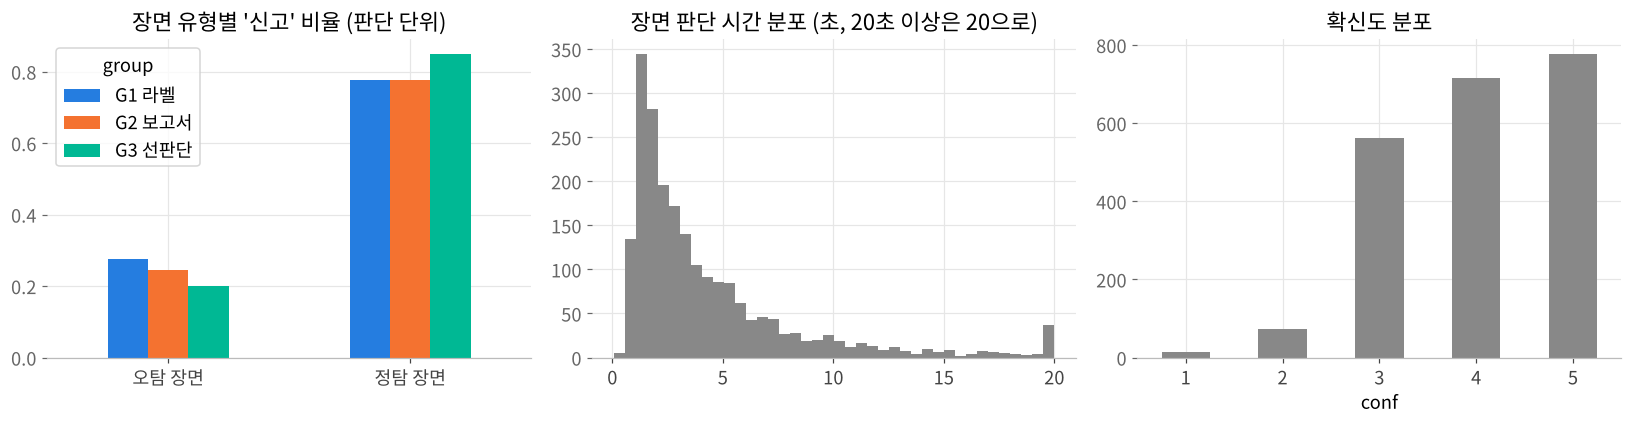

판단 시간 중앙값: 2.89 초 · 평균: 4.49 초 → 오른쪽 꼬리가 길어 중앙값 사용


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
tr.groupby(["truth", "group"]).report.mean().unstack().rename(index={0: "오탐 장면", 1: "정탐 장면"}, columns=GNAME).plot.bar(ax=ax[0], rot=0, color=[COL["G1"], COL["G2"], COL["G3"]])
ax[0].set_title("장면 유형별 '신고' 비율 (판단 단위)"); ax[0].set_xlabel("")
(tr.view_rt / 1000).clip(upper=20).hist(bins=40, ax=ax[1], color="#888"); ax[1].set_title("장면 판단 시간 분포 (초, 20초 이상은 20으로)")
tr.conf.value_counts().sort_index().plot.bar(ax=ax[2], rot=0, color="#888"); ax[2].set_title("확신도 분포")
plt.tight_layout(); plt.show()
print("판단 시간 중앙값:", round(tr.view_rt.median() / 1000, 2), "초 · 평균:", round(tr.view_rt.mean() / 1000, 2), "초 → 오른쪽 꼬리가 길어 중앙값 사용")

In [10]:
# 총 소요시간 분포 (분 단위로 잘린 값)
print(pv.TIME_total.value_counts().sort_index().to_dict())

{2.0: 6, 3.0: 31, 4.0: 40, 5.0: 18, 6.0: 10, 7.0: 4, 8.0: 2, 9.0: 3, 10.0: 1, 12.0: 1, 13.0: 1}


## 4. 참가자별 KPI 계산

같은 사람이 18번 판단하므로 판단 2,142개는 서로 독립이 아니다. → **사람마다 비율 하나로 줄인 뒤** 그룹을 비교한다.

| KPI | 계산 | 뜻 |
|---|---|---|
| 오탐 수용률 (FA) | 오탐 6장면 중 신고 비율 | 틀린 AI를 따른 정도 = 자동화 편향 (낮을수록 좋음) |
| 정탐 신고율 (Hit) | 정탐 12장면 중 신고 비율 | 실제 사건을 잡은 정도 (높을수록 좋음) |
| 정답률 | 18장면 중 정답 비율 | 참고용 (전부 신고만 해도 67% → 메인 X) |
| 균형 정답률 | (Hit + (1 − FA)) / 2 | 12:6 불균형 보정 정답률 (보조 지표) |
| **판별력 d′** | z(Hit) − z(FA) | 진짜와 오탐을 구분하는 능력 (**메인 지표**) |
| 기준 c | −(z(Hit) + z(FA)) / 2 | 0보다 작으면 '일단 신고' 쪽으로 기운 상태 |

**로그선형 보정 (Hautus, 1995)**: z점수는 0%·100%에서 무한대가 되므로, 모든 사람에게 (신고 개수 + 0.5) / (장면 수 + 1)을 적용한다. 덜 편향되고 항상 약간 작게(보수적으로) 추정되는 표준 방법이다.

G3는 같은 지표를 **1단계(AI 없이)** 판단으로도 계산한다 → "AI 없이" 기준선.

In [11]:
def sdt(x, col):
    nh, nf = (x.truth == 1).sum(), (x.truth == 0).sum()
    H = (x.loc[x.truth == 1, col].sum() + .5) / (nh + 1)
    F = (x.loc[x.truth == 0, col].sum() + .5) / (nf + 1)
    return norm.ppf(H) - norm.ppf(F), -(norm.ppf(H) + norm.ppf(F)) / 2

recs = []
for pid, x in tr.groupby("pid"):
    fa, hit = x[x.truth == 0], x[x.truth == 1]
    d, c = sdt(x, "report")
    r = dict(pid=pid, group=x.group.iloc[0],
             fa=fa.report.mean(), hit=hit.report.mean(), acc=x.correct.mean(),
             bal=(hit.report.mean() + 1 - fa.report.mean()) / 2, dp=d, c=c,
             rt_fa=fa.view_rt.median() / 1000, conf_fa=fa.conf.mean())
    if r["group"] == 3:
        d1, c1 = sdt(x, "first")
        r.update(fa1=fa["first"].mean(), hit1=hit["first"].mean(),
                 bal1=(hit["first"].mean() + 1 - fa["first"].mean()) / 2, dp1=d1, c1=c1)
    recs.append(r)
P = pd.DataFrame(recs).set_index("pid")
P = P.round(10)   # 부동소수점 오차 제거: 같은 값(예: 0.75)이 미세하게 달라져 순위검정에서 동점 처리가 안 되는 문제 방지
P = P.join(pv)
print("0% 또는 100%가 하나라도 있는 참가자:", int(((P.fa.isin([0, 1])) | (P.hit.isin([0, 1]))).sum()), "/", len(P), "→ 보정이 필요한 이유")
P[["fa", "hit", "acc", "bal", "dp", "c", "rt_fa", "conf_fa"]].describe().round(3)

0% 또는 100%가 하나라도 있는 참가자: 67 / 119 → 보정이 필요한 이유


,fa,hit,acc,bal,dp,c,rt_fa,conf_fa
count,119.000,119.000,119.000,119.000,119.000,119.000,119.000,119.000
mean,0.241,0.800,0.786,0.779,1.611,-0.105,4.590,3.622
std,0.248,0.182,0.121,0.126,0.759,0.558,3.153,0.577
min,0.000,0.333,0.500,0.500,0.030,-1.617,1.234,1.667
25%,0.000,0.667,0.722,0.708,1.070,-0.489,2.207,3.167
50%,0.167,0.833,0.778,0.792,1.659,-0.097,3.574,3.667
75%,0.333,1.000,0.889,0.875,2.108,0.298,5.660,4.000
max,1.000,1.000,1.000,1.000,3.234,0.930,15.505,5.000


In [12]:
# 그룹 요약표 (4개 조건: AI 없이 = G3 1단계)
rng = np.random.default_rng(7)
def ci(v, n=10000):
    v = np.asarray(pd.Series(v).dropna()); m = rng.choice(v, (n, len(v))).mean(1)
    return v.mean(), *np.percentile(m, [2.5, 97.5])

G = {g: P[P.group == g] for g in (1, 2, 3)}
cond = {"AI 없이(G3 1단계)": (G[3], "1"), "G3 최종": (G[3], ""), "G2 보고서": (G[2], ""), "G1 라벨": (G[1], "")}
summ = {}
for name, (df, suf) in cond.items():
    row = {}
    for k in ["fa", "hit", "bal", "dp", "c"]:
        m, lo, hi = ci(df[k + suf])
        row[k] = f"{m:.3f} [{lo:.3f}, {hi:.3f}]"
    row["n"] = len(df)
    summ[name] = row
pd.DataFrame(summ).rename(index={"fa": "오탐 수용률", "hit": "정탐 신고율", "bal": "균형 정답률", "dp": "판별력 d′", "c": "기준 c"})

,AI 없이(G3 1단계),G3 최종,G2 보고서,G1 라벨
오탐 수용률,"0.150 [0.094, 0.214]","0.201 [0.128, 0.278]","0.244 [0.171, 0.321]","0.276 [0.199, 0.358]"
정탐 신고율,"0.808 [0.754, 0.861]","0.848 [0.799, 0.893]","0.776 [0.722, 0.829]","0.776 [0.711, 0.835]"
균형 정답률,"0.829 [0.796, 0.862]","0.824 [0.788, 0.858]","0.766 [0.726, 0.806]","0.750 [0.710, 0.789]"
판별력 d′,"1.903 [1.700, 2.112]","1.899 [1.689, 2.106]","1.515 [1.267, 1.770]","1.427 [1.206, 1.646]"
기준 c,"0.021 [-0.135, 0.176]","-0.127 [-0.304, 0.044]","-0.061 [-0.218, 0.092]","-0.126 [-0.312, 0.052]"
n,39,39,39,41


## 5. 가설 검정

**검정 방법**: 비율 데이터는 0%에 몰리는 등 정규분포가 아니므로 **비모수 검정** 사용.
- 세 그룹 비교: Kruskal-Wallis (효과크기 ε²)
- 두 그룹 비교: Mann-Whitney U (효과크기 순위이연 상관 r, 다중비교는 Holm 보정)
- 같은 사람 전·후 비교: Wilcoxon 부호순위

In [13]:
def holm(ps):
    o = np.argsort(ps); adj = np.empty(len(ps)); m = 0
    for k, i in enumerate(o):
        m = max(m, min(1, ps[i] * (len(ps) - k))); adj[i] = m
    return adj

def compare3(col, label):
    gs = [G[g][col].dropna() for g in (1, 2, 3)]
    H, p = stats.kruskal(*gs); n = sum(map(len, gs)); eps = (H - 2) / (n - 3)
    raw = []
    for a, b in [(1, 2), (1, 3), (2, 3)]:
        u, pv_ = stats.mannwhitneyu(gs[a - 1], gs[b - 1], alternative="two-sided")
        raw.append((f"G{a}-G{b}", pv_, 1 - 2 * u / (len(gs[a - 1]) * len(gs[b - 1]))))
    adj = holm([r[1] for r in raw])
    pairs = " · ".join(f"{n_} p(Holm)={a:.3f} r={r:+.2f}" for (n_, _, r), a in zip(raw, adj))
    return dict(지표=label, G1=gs[0].mean(), G2=gs[1].mean(), G3=gs[2].mean(), H=H, p=p, ε2=eps, 사후비교=pairs)

T = pd.DataFrame([compare3("fa", "오탐 수용률"), compare3("hit", "정탐 신고율"), compare3("bal", "균형 정답률"),
                  compare3("dp", "판별력 d′"), compare3("c", "기준 c"), compare3("rt_fa", "오탐 판단시간(초)"),
                  compare3("conf_fa", "오탐 확신도"), compare3("basis_ai", "AI 참고(자기보고)")])
T.round(3)

,지표,G1,G2,G3,H,p,ε2,사후비교
0,오탐 수용률,0.276,0.244,0.201,2.245,0.325,0.002,G1-G2 p(Holm)=0.698 r=-0.06 · G1-G3 p(Holm)=0....
1,정탐 신고율,0.776,0.776,0.848,3.735,0.155,0.015,G1-G2 p(Holm)=0.785 r=-0.04 · G1-G3 p(Holm)=0....
2,균형 정답률,0.750,0.766,0.824,7.589,0.022,0.048,G1-G2 p(Holm)=0.695 r=+0.05 · G1-G3 p(Holm)=0....
3,판별력 d′,1.427,1.515,1.899,8.950,0.011,0.060,G1-G2 p(Holm)=0.791 r=+0.04 · G1-G3 p(Holm)=0....
4,기준 c,-0.126,-0.061,-0.127,0.290,0.865,-0.015,G1-G2 p(Holm)=1.000 r=+0.07 · G1-G3 p(Holm)=1....
5,오탐 판단시간(초),3.914,6.557,3.335,24.640,0.000,0.195,G1-G2 p(Holm)=0.000 r=+0.49 · G1-G3 p(Holm)=0....
6,오탐 확신도,3.569,3.560,3.739,3.398,0.183,0.012,G1-G2 p(Holm)=0.985 r=+0.00 · G1-G3 p(Holm)=0....
7,AI 참고(자기보고),2.902,2.923,3.436,7.499,0.024,0.047,G1-G2 p(Holm)=0.948 r=-0.01 · G1-G3 p(Holm)=0....


### 5-1. 핵심: "AI 없이" 기준선과 비교

1차 분석은 세 그룹(모두 AI를 봄)끼리만 비교해서 차이가 안 보였다. **G3 1단계(AI 없이)** 를 기준선으로 놓고 비교한다.

In [14]:
def vs_noai(col1, col, label):
    base = G[3][col1]
    out = {"지표": label, "AI 없이": base.mean()}
    for g, n_ in [(1, "G1"), (2, "G2")]:
        out[n_] = G[g][col].mean(); out[f"p (vs {n_})"] = stats.mannwhitneyu(base, G[g][col]).pvalue
    out["p (vs G1+G2)"] = stats.mannwhitneyu(base, pd.concat([G[1][col], G[2][col]])).pvalue
    return out
B = pd.DataFrame([vs_noai("fa1", "fa", "오탐 수용률"), vs_noai("hit1", "hit", "정탐 신고율"),
                  vs_noai("bal1", "bal", "균형 정답률"), vs_noai("dp1", "dp", "판별력 d′")])
display(B.round(3))

# 차이의 95% 부트스트랩 신뢰구간 (G1 − AI 없이, 오탐 수용률)
a, b = G[1].fa.values, G[3].fa1.values
bs = [rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean() for _ in range(10000)]
print(f"오탐 수용률 차이 G1 − AI 없이 = {a.mean() - b.mean():+.3f}, 95% CI [{np.percentile(bs, 2.5):.3f}, {np.percentile(bs, 97.5):.3f}]")
print("G3 vs G1+G2 판별력 p =", round(stats.mannwhitneyu(G[3].dp, pd.concat([G[1].dp, G[2].dp])).pvalue, 4))

,지표,AI 없이,G1,p (vs G1),G2,p (vs G2),p (vs G1+G2)
0,오탐 수용률,0.150,0.276,0.015,0.244,0.060,0.013
1,정탐 신고율,0.808,0.776,0.636,0.776,0.397,0.447
2,균형 정답률,0.829,0.750,0.006,0.766,0.022,0.004
3,판별력 d′,1.903,1.427,0.005,1.515,0.019,0.003


오탐 수용률 차이 G1 − AI 없이 = +0.127, 95% CI [0.028, 0.229]
G3 vs G1+G2 판별력 p = 0.003


### 5-2. (보충) 판단 단위 로지스틱 GEE

사람 단위로 줄이지 않고, 판단 2,142개를 쓰되 **같은 사람의 판단끼리 상관이 있음을 반영**하는 모형(GEE, 교환 상관 구조). 결과 방향이 사람 단위 분석과 같은지 확인용. (statsmodels 필요)

In [15]:
try:
    import statsmodels.api as sm, statsmodels.formula.api as smf
    d = tr.assign(g=tr.group.astype(str))
    for t, n_ in [(0, "오탐 장면 신고"), (1, "정탐 장면 신고")]:
        m = smf.gee("report ~ C(g)", groups="pid", data=d[d.truth == t], family=sm.families.Binomial(),
                    cov_struct=sm.cov_struct.Exchangeable()).fit()
        print(n_, "| 오즈비(G1 기준):", np.exp(m.params).round(2).to_dict(), "| p:", m.pvalues.round(3).to_dict())
except ImportError:
    print("statsmodels가 없어 건너뜀 (pip install statsmodels)")

오탐 장면 신고 | 오즈비(G1 기준): {'Intercept': 0.38, 'C(g)[T.2]': 0.84, 'C(g)[T.3]': 0.66} | p: {'Intercept': 0.0, 'C(g)[T.2]': 0.553, 'C(g)[T.3]': 0.181}
정탐 장면 신고 | 오즈비(G1 기준): {'Intercept': 3.47, 'C(g)[T.2]': 1.0, 'C(g)[T.3]': 1.61} | p: {'Intercept': 0.0, 'C(g)[T.2]': 0.985, 'C(g)[T.3]': 0.069}


## 6. G3 내부 분석: AI를 보기 전 → 후

같은 사람이 AI 없이 판단한 뒤 AI 표시를 보고 최종 판단했으므로 **Wilcoxon 부호순위 검정**으로 전후 비교.

In [16]:
x = G[3]
for k1, k, n_ in [("fa1", "fa", "오탐 수용률"), ("hit1", "hit", "정탐 신고율"), ("dp1", "dp", "판별력 d′"), ("c1", "c", "기준 c")]:
    w = stats.wilcoxon(x[k1], x[k], zero_method="zsplit")
    print(f"{n_}: 1단계 {x[k1].mean():.3f} → 최종 {x[k].mean():.3f}  (Wilcoxon p={w.pvalue:.3f})")

오탐 수용률: 1단계 0.150 → 최종 0.201  (Wilcoxon p=0.175)
정탐 신고율: 1단계 0.808 → 최종 0.848  (Wilcoxon p=0.061)
판별력 d′: 1단계 1.903 → 최종 1.899  (Wilcoxon p=0.817)
기준 c: 1단계 0.021 → 최종 -0.127  (Wilcoxon p=0.037)


### 6-1. 판단 전환: 내 판단과 AI가 다를 때

- **이로운 전환**: 정탐인데 1단계에서 놓침 → AI 보고 신고
- **해로운 전환**: 오탐을 1단계에서 맞게 무시 → AI 보고 신고

두 가지로 계산한다: (a) 해당 판단을 모두 합쳐서, (b) 참가자별 비율의 평균. 발표에서는 한 가지로 통일.

In [17]:
g3 = tr[tr.group == 3]
help_ = g3[(g3.truth == 1) & (g3["first"] == 0)]; harm = g3[(g3.truth == 0) & (g3["first"] == 0)]
back = g3[(g3.truth == 0) & (g3["first"] == 1)]
print(f"(a) 합산 — 이로운 전환 {help_.report.mean():.1%} (n={len(help_)}) · 해로운 전환 {harm.report.mean():.1%} (n={len(harm)})")
print(f"(b) 참가자별 평균 — 이로운 {help_.groupby('pid').report.mean().mean():.1%} · 해로운 {harm.groupby('pid').report.mean().mean():.1%}")
print(f"참고: 1단계에서 오탐을 신고했다가 AI 화면에서 무시로 바꾼 비율 {1 - back.report.mean():.1%} (n={len(back)})")

(a) 합산 — 이로운 전환 25.6% (n=90) · 해로운 전환 10.1% (n=199)
(b) 참가자별 평균 — 이로운 25.0% · 해로운 11.8%
참고: 1단계에서 오탐을 신고했다가 AI 화면에서 무시로 바꾼 비율 22.9% (n=35)


## 7. 장면·유형 단위 분석

In [18]:
sc = pd.DataFrame({"AI 없이": g3.groupby("scene")["first"].mean(), "G3 최종": g3.groupby("scene").report.mean(),
                   "G2": tr[tr.group == 2].groupby("scene").report.mean(), "G1": tr[tr.group == 1].groupby("scene").report.mean()})
sc = scenes.set_index("scene")[["label", "truth", "day_night"]].join(sc, how="inner")
sc["AI 효과(G1−AI없이)"] = sc.G1 - sc["AI 없이"]
display(sc.round(2))
fa_sc = sc[sc.truth == "오탐"]
k = int((fa_sc["AI 효과(G1−AI없이)"] > 0).sum())
print(f"오탐 {len(fa_sc)}장면 중 AI 표시로 신고가 늘어난 장면: {k}개  (부호검정 p={stats.binomtest(k, len(fa_sc)).pvalue:.3f})")

,label,truth,day_night,AI 없이,G3 최종,G2,G1,AI 효과(G1−AI없이)
scene,,,,,,,,
S01,싸움,정탐,밤,0.79,0.85,0.92,0.95,0.16
S02,싸움,정탐,낮,0.62,0.69,0.38,0.41,-0.20
S03,싸움,정탐,밤,0.92,0.97,0.74,0.83,-0.09
S04,싸움,정탐,밤,0.95,0.95,0.90,0.90,-0.05
S05,쓰러짐,정탐,낮,0.95,0.97,0.95,0.90,-0.05
S06,쓰러짐,정탐,밤,0.90,0.90,0.72,0.78,-0.12
S07,쓰러짐,정탐,밤,0.92,0.95,0.95,0.93,0.00
S08,쓰러짐,정탐,낮,0.97,1.00,1.00,1.00,0.03
S09,침입,정탐,낮,0.69,0.77,0.77,0.59,-0.11


오탐 6장면 중 AI 표시로 신고가 늘어난 장면: 6개  (부호검정 p=0.031)


In [19]:
# 이벤트 유형 · 주야별
def by(col):
    a = tr.groupby(["truth", col, "group"]).report.mean().unstack().rename(columns=GNAME)
    a["AI 없이"] = g3.groupby(["truth", col])["first"].mean()
    return a.rename(index={0: "오탐", 1: "정탐"}).round(3)
display(by("label")); display(by("day_night"))

group        G1 라벨  G2 보고서  G3 선판단  AI 없이
truth label                              
오탐    싸움     0.293   0.282   0.231  0.167
      쓰러짐    0.378   0.295   0.269  0.167
      침입     0.159   0.154   0.103  0.115
정탐    싸움     0.774   0.737   0.865  0.821
      쓰러짐    0.902   0.904   0.955  0.936
      침입     0.652   0.686   0.724  0.667

group            G1 라벨  G2 보고서  G3 선판단  AI 없이
truth day_night                              
오탐    낮          0.293   0.231   0.224  0.173
      밤          0.244   0.269   0.154  0.103
정탐    낮          0.704   0.725   0.795  0.744
      밤          0.878   0.846   0.923  0.897

## 8. 판단 시간 · 확신도 · 학습 효과

In [20]:
# 확신도: 틀린 알람을 따랐을 때 vs 맞게 무시했을 때
f = tr[tr.truth == 0]
print(f"오탐 신고(틀림) 확신도 {f[f.report == 1].conf.mean():.2f} vs 오탐 무시(맞음) {f[f.report == 0].conf.mean():.2f}")
print(f"오탐을 따른 경우 중 확신도 4 이상: {(f[f.report == 1].conf >= 4).mean():.1%}  (n={int(f.report.sum())})")
display(tr.groupby(["group", "truth", "correct"]).conf.mean().unstack().rename(index=GNAME).round(2))

# 판단 시간: 따랐을 때 vs 무시했을 때 (같은 사람 안에서)
m = f.groupby(["pid", "report"]).view_rt.median().unstack().dropna()
print(f"오탐 장면 판단시간(초) 따름 {m[1].median()/1000:.2f} vs 무시 {m[0].median()/1000:.2f}  (Wilcoxon p={stats.wilcoxon(m[1], m[0]).pvalue:.3f}, n={len(m)})")

오탐 신고(틀림) 확신도 3.54 vs 오탐 무시(맞음) 3.65
오탐을 따른 경우 중 확신도 4 이상: 52.3%  (n=172)


correct          0     1
group  truth            
G1 라벨  0      3.29  3.67
       G1 라벨  3.62  4.36
G2 보고서 0      3.54  3.56
       G1 라벨  3.39  4.27
G3 선판단 0      3.89  3.70
       G1 라벨  3.54  4.50

오탐 장면 판단시간(초) 따름 3.80 vs 무시 3.94  (Wilcoxon p=0.190, n=75)


In [21]:
# 학습 효과: 오탐을 몇 번째로 만났는지에 따라 수용률이 줄어드는가? (피드백 없음)
f = tr[tr.truth == 0].sort_values(["pid", "pos"]).copy()
f["k"] = f.groupby("pid").cumcount() + 1
display(f.groupby(["group", "k"]).report.mean().unstack().rename(index=GNAME).round(2))
r, p = stats.spearmanr(f.k, f.report)
print(f"오탐 순서 vs 신고: ρ={r:.3f}, p={p:.3f} → 실험이 진행돼도 AI를 덜 믿게 되지 않음")

k,1,2,3,4,5,6
group,,,,,,
G1 라벨,0.34,0.27,0.27,0.22,0.27,0.29
G2 보고서,0.15,0.26,0.28,0.28,0.18,0.31
G3 선판단,0.28,0.28,0.13,0.13,0.21,0.18


오탐 순서 vs 신고: ρ=-0.019, p=0.609 → 실험이 진행돼도 AI를 덜 믿게 되지 않음


## 9. 설문 vs 행동 (Spearman 상관)

자기보고(신뢰, AI 참고 정도)가 실제 행동(오탐 수용률, 판별력)과 맞는지 확인한다.

In [22]:
items = {"basis_ai": "AI 표시 참고", "basis_scene": "장면 참고", "basis_report": "보고서 참고(G2)",
         "trust1": "AI 정확했다", "trust2": "AI 믿고 판단", "trust3": "실관제라면 신뢰",
         "ai_trust_general": "평소 AI 신뢰", "ai_use": "AI 사용빈도"}
rows = []
for k_, n_ in items.items():
    z = P[[k_, "fa", "dp"]].dropna()
    r1, p1 = stats.spearmanr(z[k_], z.fa); r2, p2 = stats.spearmanr(z[k_], z.dp)
    rows.append(dict(문항=n_, n=len(z), ρ_오탐수용률=r1, p1=p1, ρ_판별력=r2, p2=p2))
display(pd.DataFrame(rows).round(3))
display(P.groupby("group")[["basis_scene", "basis_ai", "basis_report", "trust1", "trust2", "trust3"]].mean().rename(index=GNAME).round(2))

,문항,n,ρ_오탐수용률,p1,ρ_판별력,p2
0,AI 표시 참고,119,0.104,0.261,0.004,0.965
1,장면 참고,119,-0.037,0.688,0.088,0.341
2,보고서 참고(G2),39,-0.083,0.616,0.304,0.060
3,AI 정확했다,119,0.171,0.062,0.033,0.721
4,AI 믿고 판단,119,0.156,0.091,-0.099,0.282
5,실관제라면 신뢰,119,0.207,0.024,0.024,0.794
6,평소 AI 신뢰,119,0.122,0.185,-0.181,0.049
7,AI 사용빈도,119,0.004,0.969,-0.133,0.148


,basis_scene,basis_ai,basis_report,trust1,trust2,trust3
group,,,,,,
G1 라벨,4.46,2.90,NaN,3.63,3.1,3.34
G2 보고서,4.38,2.92,3.21,3.33,2.9,3.26
G3 선판단,3.87,3.44,NaN,3.74,3.1,3.56


## 10. 민감도 분석 · 검정력

### 10-1. 의심 응답자를 빼도 결과가 같은가
- 총 소요시간 2분 이하 (PsyToolkit은 분 단위로 잘라서 기록)
- 18장면 모두 같은 답 (이번 데이터에서는 전부 '모두 신고' → 자동화 편향의 극단일 수 있어 **본 분석에서는 제외하지 않음**)

In [23]:
short = set(P.index[P.TIME_total <= 2]); same = set(P.index[(P.hit == P.fa) & P.hit.isin([0, 1])])
print("2분 이하:", len(short), "명 · 모두 같은 답:", len(same), "명", P.loc[list(same), ["group", "hit", "fa"]].to_dict("records"))
def run(excl, name):
    Q = P.drop(index=list(excl))
    base, g1, g12 = Q[Q.group == 3].fa1, Q[Q.group == 1].fa, Q[Q.group < 3].fa
    kw = stats.kruskal(*[Q[Q.group == g].dp for g in (1, 2, 3)]).pvalue
    return dict(조건=name, N=len(Q), AI없이=base.mean(), G1=g1.mean(), p_vsG1=stats.mannwhitneyu(base, g1).pvalue,
                p_vsG12=stats.mannwhitneyu(base, g12).pvalue, 판별력_KW_p=kw)
pd.DataFrame([run(set(), "전체"), run(short, "2분 이하 제외"), run(same, "같은 답 제외"), run(short | same, "둘 다 제외")]).round(3)

2분 이하: 6 명 · 모두 같은 답: 3 명 [{'group': 3, 'hit': 1.0, 'fa': 1.0}, {'group': 1, 'hit': 1.0, 'fa': 1.0}, {'group': 1, 'hit': 1.0, 'fa': 1.0}]


,조건,N,AI없이,G1,p_vsG1,p_vsG12,판별력_KW_p
0,전체,119,0.15,0.276,0.015,0.013,0.011
1,2분 이하 제외,113,0.15,0.288,0.013,0.012,0.009
2,같은 답 제외,116,0.14,0.239,0.020,0.012,0.009
3,둘 다 제외,110,0.14,0.248,0.020,0.012,0.009


In [24]:
# 10-2. 검정력: 그룹당 약 40명으로 잡을 수 있는 효과 크기
try:
    from statsmodels.stats.power import TTestIndPower
    pw = TTestIndPower()
    print("그룹당 40명, 80% 검정력으로 잡을 수 있는 최소 효과크기 d =", round(pw.solve_power(nobs1=40, alpha=.05, power=.8), 2))
    a, b = G[1].fa, G[3].fa
    d = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
    print(f"G1 vs G3 최종 오탐 수용률 효과크기 d = {d:.2f} → 필요 인원 그룹당 {pw.solve_power(effect_size=d, alpha=.05, power=.8):.0f}명")
except ImportError:
    print("statsmodels가 없어 건너뜀")

그룹당 40명, 80% 검정력으로 잡을 수 있는 최소 효과크기 d = 0.63


G1 vs G3 최종 오탐 수용률 효과크기 d = 0.30 → 필요 인원 그룹당 176명


## 11. 발표용 차트

막대 끝 선 = 95% 부트스트랩 신뢰구간. `results/charts/` 폴더에 PNG로 저장된다.

In [25]:
TXT2 = "#666666"
def title(ax, t, s=None):
    ax.set_title(t, loc="left", fontsize=16, fontweight="bold", pad=28 if s else 12)
    if s: ax.text(0, 1.02, s, transform=ax.transAxes, fontsize=11.5, color=TXT2, va="bottom")
def bars(ax, vals, labels, cols, fmt="{:.1%}", ylim=None, pct=True):
    x = np.arange(len(vals)); m = [v[0] for v in vals]
    ax.bar(x, m, width=.56, color=cols, edgecolor="white", linewidth=2)
    ax.errorbar(x, m, yerr=[[v[0] - v[1] for v in vals], [v[2] - v[0] for v in vals]], fmt="none", ecolor="#333", elinewidth=1.4, capsize=5)
    for i, v in enumerate(vals):
        ax.text(i, v[2] + (ylim[1] * .02 if ylim else .01), fmt.format(v[0]), ha="center", va="bottom", fontsize=13, fontweight="bold")
    ax.set_xticks(x, labels); ax.tick_params(axis="x", length=0)
    if ylim: ax.set_ylim(*ylim)
    if pct: ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0))
def save(fig, name):
    fig.tight_layout(); fig.savefig(f"{OUT}/{name}.png", dpi=200, facecolor="white"); plt.show()

L4 = ["AI 없이\n(G3 1단계)", "G3 먼저 판단\n(최종)", "G2 라벨+보고서", "G1 라벨만"]
C4 = [COL["noAI"], COL["G3"], COL["G2"], COL["G1"]]

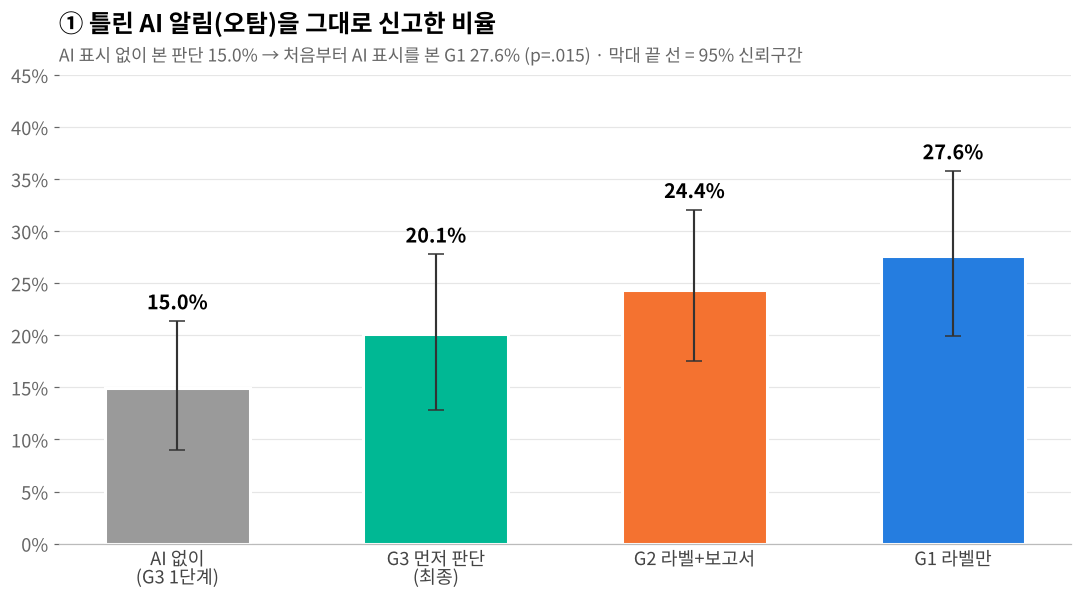

In [26]:
# ① 오탐 수용률
fig, ax = plt.subplots(figsize=(10, 5.6))
bars(ax, [ci(G[3].fa1), ci(G[3].fa), ci(G[2].fa), ci(G[1].fa)], L4, C4, ylim=(0, .45))
title(ax, "① 틀린 AI 알림(오탐)을 그대로 신고한 비율", "AI 표시 없이 본 판단 15.0% → 처음부터 AI 표시를 본 G1 27.6% (p=.015) · 막대 끝 선 = 95% 신뢰구간")
save(fig, "01_오탐수용률")

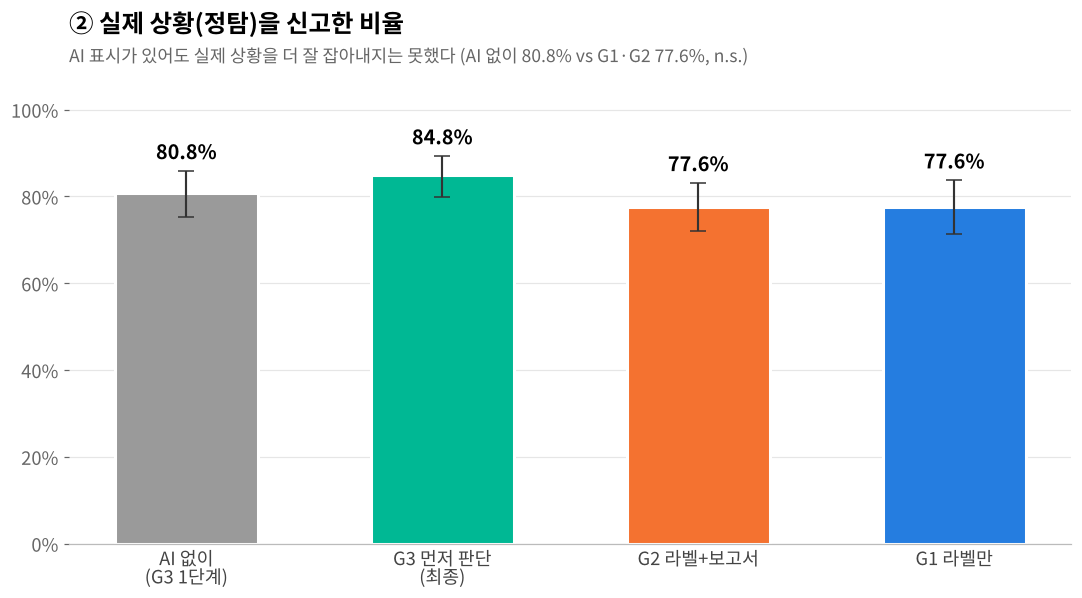

In [27]:
# ② 정탐 신고율
fig, ax = plt.subplots(figsize=(10, 5.6))
bars(ax, [ci(G[3].hit1), ci(G[3].hit), ci(G[2].hit), ci(G[1].hit)], L4, C4, ylim=(0, 1.08))
title(ax, "② 실제 상황(정탐)을 신고한 비율", "AI 표시가 있어도 실제 상황을 더 잘 잡아내지는 못했다 (AI 없이 80.8% vs G1·G2 77.6%, n.s.)")
save(fig, "02_정탐신고율")

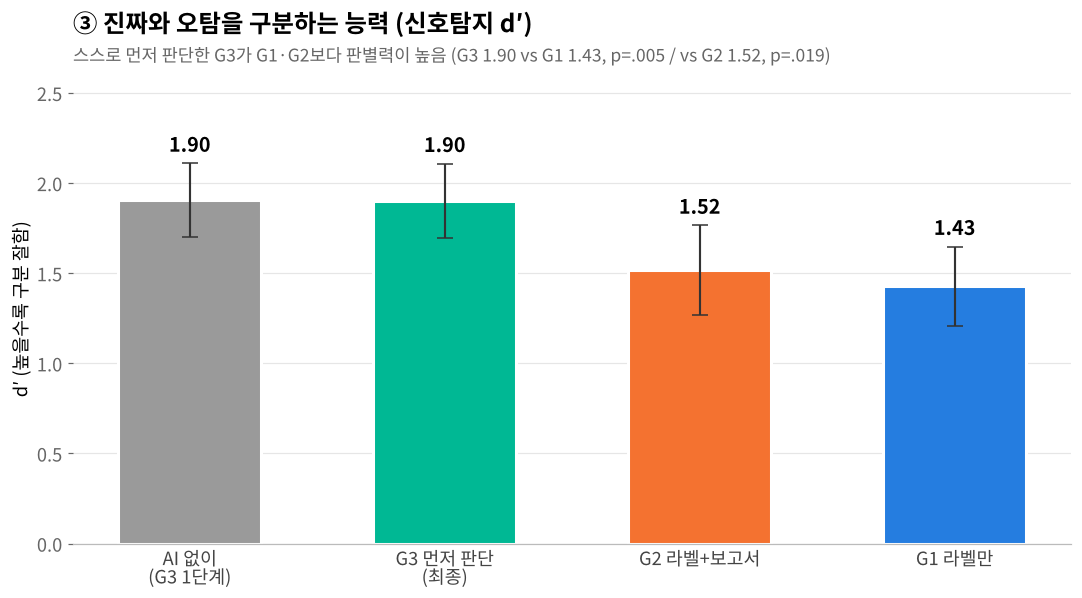

In [28]:
# ③ 판별력 d′
fig, ax = plt.subplots(figsize=(10, 5.6))
bars(ax, [ci(G[3].dp1), ci(G[3].dp), ci(G[2].dp), ci(G[1].dp)], L4, C4, fmt="{:.2f}", ylim=(0, 2.6), pct=False)
ax.set_ylabel("d′ (높을수록 구분 잘함)")
title(ax, "③ 진짜와 오탐을 구분하는 능력 (신호탐지 d′)", "스스로 먼저 판단한 G3가 G1·G2보다 판별력이 높음 (G3 1.90 vs G1 1.43, p=.005 / vs G2 1.52, p=.019)")
save(fig, "03_판별력_dprime")

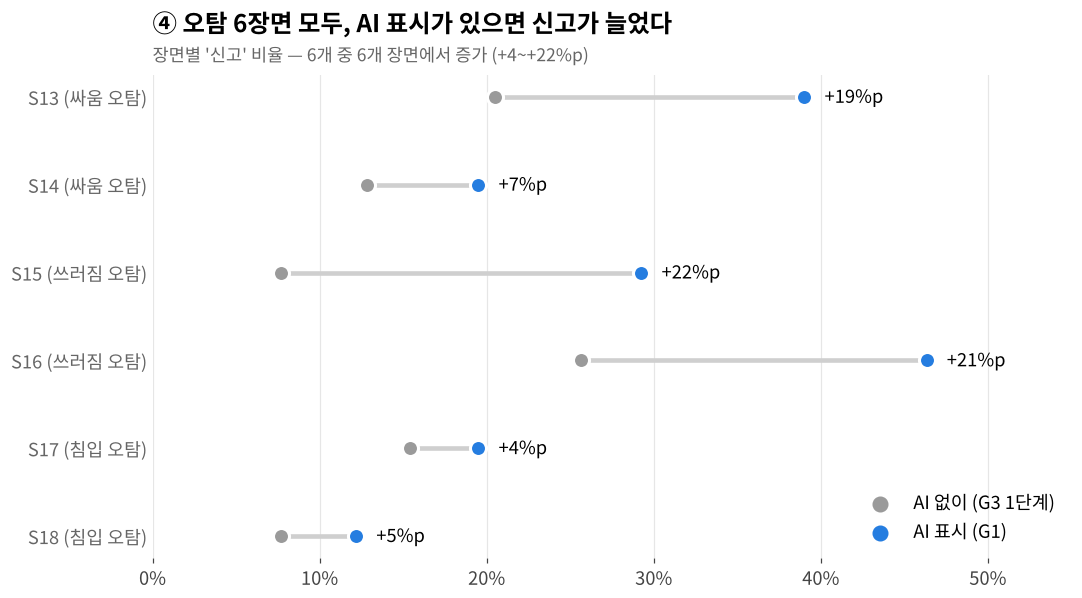

In [29]:
# ④ 오탐 장면별 AI 효과
fs = ["S13", "S14", "S15", "S16", "S17", "S18"]
fig, ax = plt.subplots(figsize=(10, 5.6)); ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
for i, s_ in enumerate(fs):
    y = len(fs) - 1 - i; a_, b_ = sc.loc[s_, "G1"], sc.loc[s_, "AI 없이"]
    ax.plot([b_, a_], [y, y], color="#cfcfcf", lw=3, zorder=1)
    ax.scatter(b_, y, s=110, color=COL["noAI"], zorder=3, edgecolor="white", linewidth=2)
    ax.scatter(a_, y, s=110, color=COL["G1"], zorder=3, edgecolor="white", linewidth=2)
    ax.text(a_ + .012, y, f"+{(a_ - b_) * 100:.0f}%p", va="center", fontsize=12)
ax.set_yticks(range(len(fs)), [f"{s_} ({sc.loc[s_, 'label']} 오탐)" for s_ in reversed(fs)]); ax.tick_params(axis="y", length=0)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0)); ax.set_xlim(0, .55); ax.spines["bottom"].set_visible(False)
ax.scatter([], [], s=90, color=COL["noAI"], label="AI 없이 (G3 1단계)"); ax.scatter([], [], s=90, color=COL["G1"], label="AI 표시 (G1)")
ax.legend(loc="lower right", frameon=False)
title(ax, "④ 오탐 6장면 모두, AI 표시가 있으면 신고가 늘었다", "장면별 '신고' 비율 — 6개 중 6개 장면에서 증가 (+4~+22%p)")
save(fig, "04_장면별_AI효과")

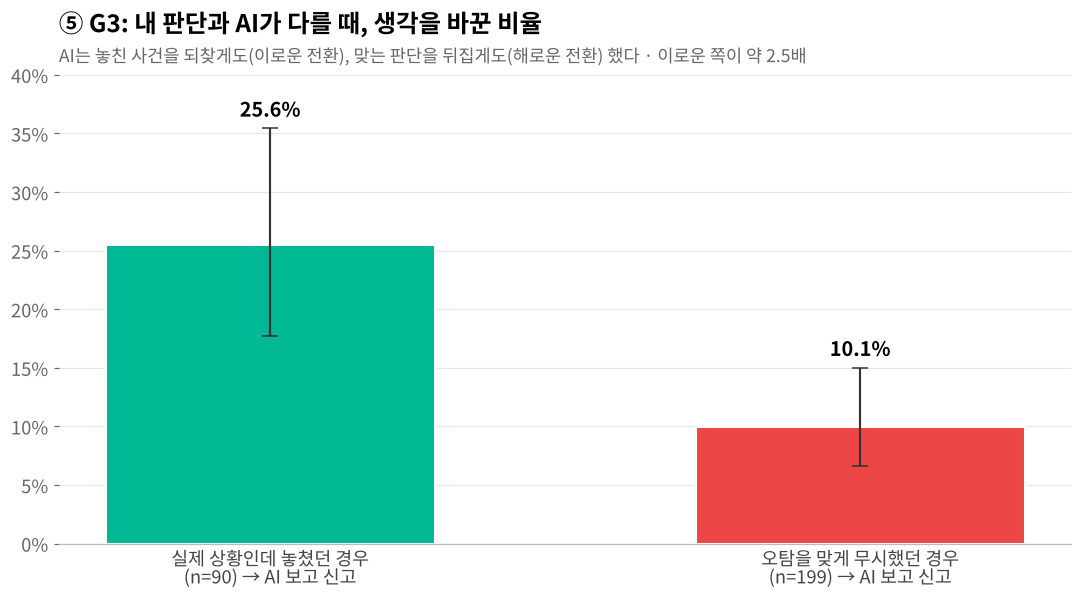

In [30]:
# ⑤ G3 판단 전환 (합산 기준, Wilson 신뢰구간)
def wilson(v):
    p = v.mean(); n = len(v); z = 1.96; dd = 1 + z * z / n; c = (p + z * z / (2 * n)) / dd
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / dd; return p, c - h, c + h
fig, ax = plt.subplots(figsize=(10, 5.6))
bars(ax, [wilson(help_.report.astype(float)), wilson(harm.report.astype(float))],
     [f"실제 상황인데 놓쳤던 경우\n(n={len(help_)}) → AI 보고 신고", f"오탐을 맞게 무시했던 경우\n(n={len(harm)}) → AI 보고 신고"],
     [COL["G3"], "#ec4647"], ylim=(0, .4))
title(ax, "⑤ G3: 내 판단과 AI가 다를 때, 생각을 바꾼 비율", "AI는 놓친 사건을 되찾게도(이로운 전환), 맞는 판단을 뒤집게도(해로운 전환) 했다 · 이로운 쪽이 약 2.5배")
save(fig, "05_G3_판단전환")

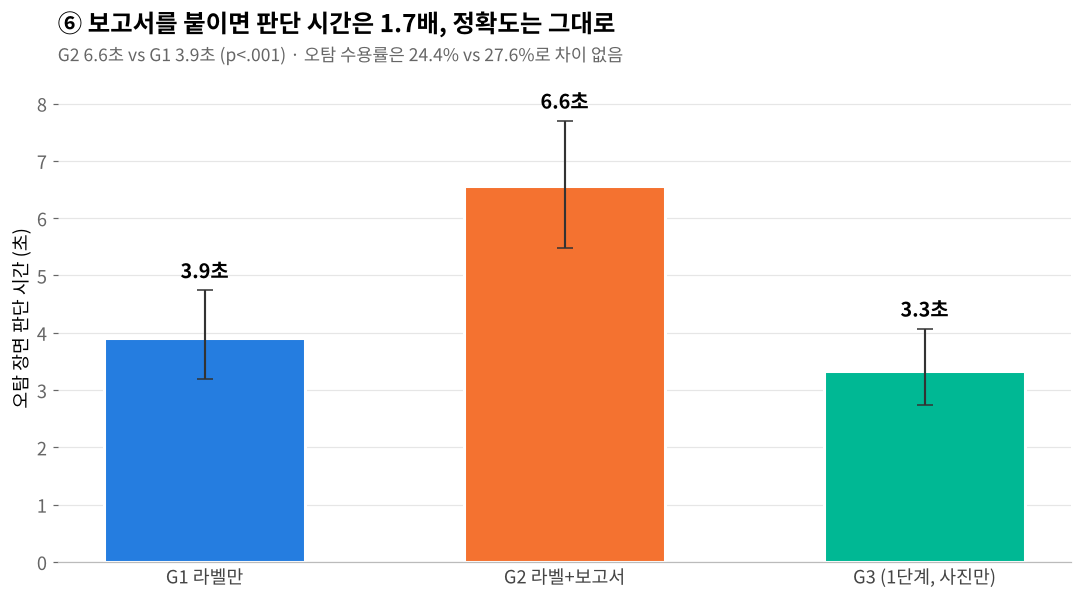

In [31]:
# ⑥ 판단 시간
fig, ax = plt.subplots(figsize=(10, 5.6))
bars(ax, [ci(G[1].rt_fa), ci(G[2].rt_fa), ci(G[3].rt_fa)], ["G1 라벨만", "G2 라벨+보고서", "G3 (1단계, 사진만)"],
     [COL["G1"], COL["G2"], COL["G3"]], fmt="{:.1f}초", ylim=(0, 8.5), pct=False)
ax.set_ylabel("오탐 장면 판단 시간 (초)")
title(ax, "⑥ 보고서를 붙이면 판단 시간은 1.7배, 정확도는 그대로", "G2 6.6초 vs G1 3.9초 (p<.001) · 오탐 수용률은 24.4% vs 27.6%로 차이 없음")
save(fig, "06_판단시간")

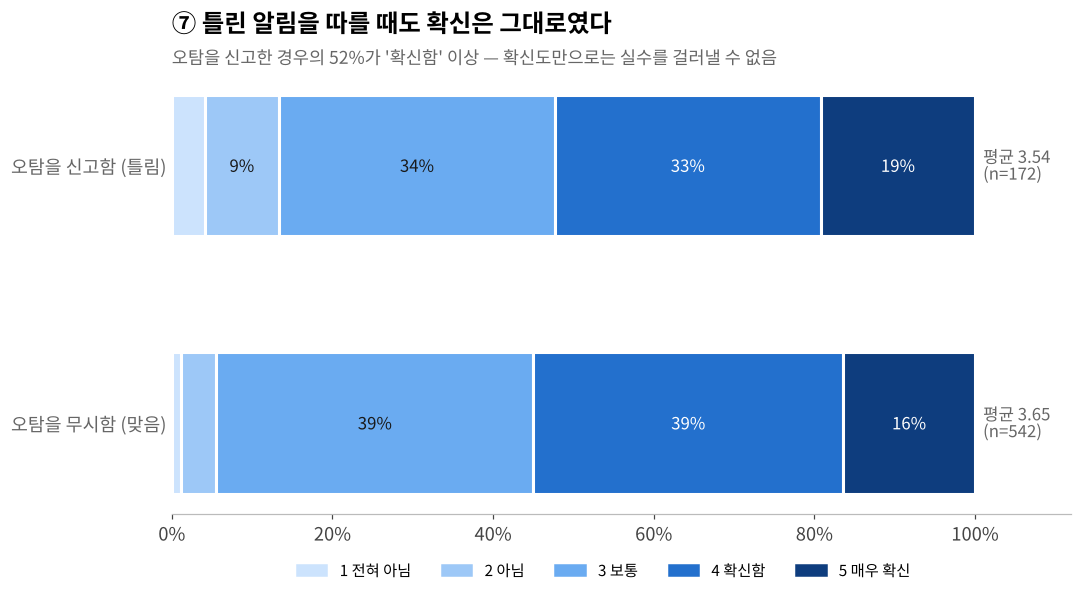

In [32]:
# ⑦ 확신도 분포
from matplotlib.patches import Patch
f = tr[tr.truth == 0]; blues = ["#cce3fd", "#9dc8f7", "#6aabf1", "#2370cd", "#0e3d7e"]
fig, ax = plt.subplots(figsize=(10, 5.6))
for i, (n_, d_) in enumerate([("오탐을 신고함 (틀림)", f[f.report == 1]), ("오탐을 무시함 (맞음)", f[f.report == 0])]):
    dist = d_.conf.value_counts(normalize=True).reindex([1, 2, 3, 4, 5], fill_value=0); left = 0
    for k_, v in dist.items():
        ax.barh(i, v, left=left, color=blues[k_ - 1], edgecolor="white", linewidth=2, height=.55)
        if v > .06: ax.text(left + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=11, color="white" if k_ >= 4 else "#191919")
        left += v
    ax.text(1.01, i, f"평균 {d_.conf.mean():.2f}\n(n={len(d_)})", va="center", fontsize=11, color=TXT2)
ax.set_yticks([0, 1], ["오탐을 신고함 (틀림)", "오탐을 무시함 (맞음)"]); ax.invert_yaxis(); ax.tick_params(axis="y", length=0)
ax.set_xlim(0, 1.12); ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0)); ax.grid(axis="y", visible=False)
ax.legend([Patch(color=c_) for c_ in blues], ["1 전혀 아님", "2 아님", "3 보통", "4 확신함", "5 매우 확신"], ncol=5, loc="upper center", bbox_to_anchor=(.48, -.08), frameon=False, fontsize=10)
title(ax, "⑦ 틀린 알림을 따를 때도 확신은 그대로였다", "오탐을 신고한 경우의 52%가 '확신함' 이상 — 확신도만으로는 실수를 걸러낼 수 없음")
save(fig, "07_확신도")

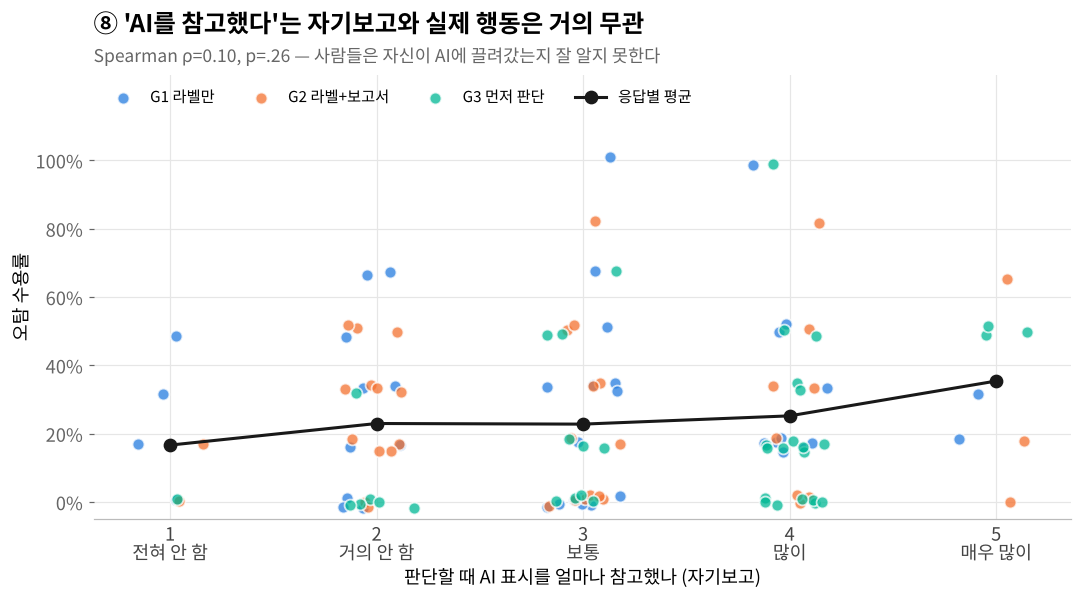

In [33]:
# ⑧ 자기보고 vs 행동
fig, ax = plt.subplots(figsize=(10, 5.6)); ax.grid(axis="x", visible=True)
for g, k_ in [(1, "G1"), (2, "G2"), (3, "G3")]:
    z = P[P.group == g]
    ax.scatter(z.basis_ai + rng.uniform(-.18, .18, len(z)), z.fa + rng.uniform(-.02, .02, len(z)), s=60, color=COL[k_], alpha=.75,
               edgecolor="white", linewidth=1.2, label={1: "G1 라벨만", 2: "G2 라벨+보고서", 3: "G3 먼저 판단"}[g])
mm = P.groupby("basis_ai").fa.mean(); ax.plot(mm.index, mm.values, color="#191919", lw=2, marker="o", ms=8, label="응답별 평균")
ax.set_xticks([1, 2, 3, 4, 5], ["1\n전혀 안 함", "2\n거의 안 함", "3\n보통", "4\n많이", "5\n매우 많이"]); ax.tick_params(axis="x", length=0)
ax.set_xlabel("판단할 때 AI 표시를 얼마나 참고했나 (자기보고)"); ax.set_ylabel("오탐 수용률")
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0)); ax.set_ylim(-.05, 1.25); ax.set_yticks([0, .2, .4, .6, .8, 1])
ax.legend(frameon=False, fontsize=10, loc="upper left", ncol=4)
title(ax, "⑧ 'AI를 참고했다'는 자기보고와 실제 행동은 거의 무관", "Spearman ρ=0.10, p=.26 — 사람들은 자신이 AI에 끌려갔는지 잘 알지 못한다")
save(fig, "08_자기보고_vs_행동")

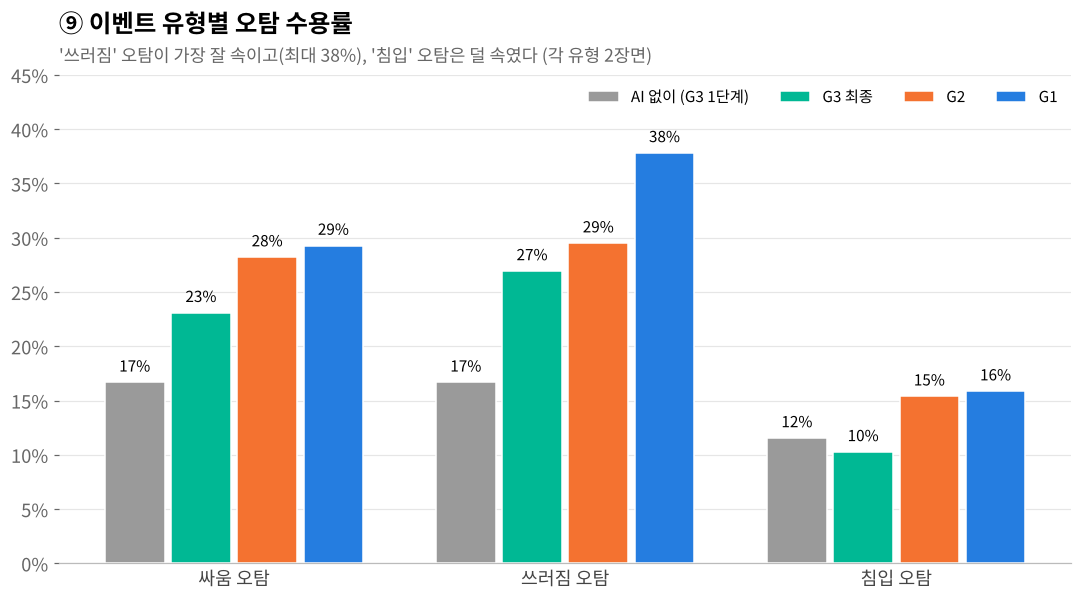

In [34]:
# ⑨ 이벤트 유형별 오탐 수용률
labs = ["싸움", "쓰러짐", "침입"]; w = .2; xx = np.arange(3)
series = [("AI 없이 (G3 1단계)", "noAI", g3, "first"), ("G3 최종", "G3", g3, "report"),
          ("G2", "G2", tr[tr.group == 2], "report"), ("G1", "G1", tr[tr.group == 1], "report")]
fig, ax = plt.subplots(figsize=(10, 5.6))
for j, (n_, k_, df, col) in enumerate(series):
    v = [df[(df.truth == 0) & (df.label == l)][col].astype(float).mean() for l in labs]
    ax.bar(xx + (j - 1.5) * w, v, width=w - .02, color=COL[k_], label=n_, edgecolor="white")
    for xi, vi in zip(xx + (j - 1.5) * w, v): ax.text(xi, vi + .01, f"{vi:.0%}", ha="center", fontsize=10)
ax.set_xticks(xx, [f"{l} 오탐" for l in labs]); ax.tick_params(axis="x", length=0)
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0)); ax.set_ylim(0, .45); ax.legend(frameon=False, ncol=4, fontsize=10)
title(ax, "⑨ 이벤트 유형별 오탐 수용률", "'쓰러짐' 오탐이 가장 잘 속이고(최대 38%), '침입' 오탐은 덜 속였다 (각 유형 2장면)")
save(fig, "09_유형별_오탐")

## 12. 결과 요약

| 가설 / 질문 | 결과 |
|---|---|
| 자동화 편향이 있는가 | **있다.** 오탐 수용률 AI 없이 15.0% → G1 27.6% (p = .015), 오탐 6장면 모두 같은 방향. 정탐 신고율은 늘지 않음 |
| H1 보고서(G2)가 더 따르게 하나 | **지지 안 됨.** G2 24.4% vs G1 27.6%. 판단 시간만 1.7배 (p < .001) |
| H2 먼저 판단(G3)이 덜 따르나 | **부분 지지.** 오탐 수용률 차이는 유의하지 않지만 판별력 d′는 G3가 유의하게 높음 (vs G1 p = .005, vs G2 p = .019) |
| H3 신뢰가 높을수록 더 따르나 | **약하게 지지.** '실관제라면 신뢰' ρ = 0.21, p = .024 |
| 사람은 편향을 알아차리나 | **모른다.** 따른 경우의 52%가 '확신함' 이상, 자기보고(AI 참고)와 행동 ρ = 0.10 |
| 견고성 | 소요시간 2분 이하·같은 답 응답자를 빼도 결론 동일 |
| 한계 | 'AI 없이'는 G3의 1단계(다른 사람) · 그룹당 약 40명 (d ≥ 0.63만 안정적으로 탐지) · 오탐 6장면 · 일반인·정지 장면·휴대폰 환경 |

**참고문헌** — Hautus, M. J. (1995). Corrections for extreme proportions and their biasing effects on estimated values of d′. *Behavior Research Methods, Instruments, & Computers*, 27(1), 46–51.